#**1) MACHINE LEARNING MODEL**


**A) Data Understanding**

Import Libraries

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.metrics import classification_report, accuracy_score
import pickle

Read Dataset

In [6]:
df = pd.read_csv('ObesityDataSet2.csv')

Display Dataset

In [8]:
df

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,24,1.58,65.29,yes,no,2.03,2.74,Sometimes,no,2.00,no,1.28,1.019,no,Public_Transportation,Overweight_Level_II
1,Male,23,1.65,66.00,no,no,3.00,3.00,Sometimes,no,2.00,no,3.00,0.000,no,Public_Transportation,Normal_Weight
2,Female,21,1.69,51.26,yes,yes,3.00,3.18,Frequently,no,1.91,no,0.48,0.625,no,Public_Transportation,Insufficient_Weight
3,Female,22,1.69,65.00,yes,yes,2.00,3.00,Sometimes,no,2.00,no,1.00,1.000,Sometimes,Public_Transportation,Normal_Weight
4,Female,23,1.61,82.64,yes,yes,2.96,1.00,Sometimes,no,2.98,no,0.74,2.000,Sometimes,Public_Transportation,Obesity_Type_I
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1051,Female,21,1.74,130.93,yes,yes,3.00,3.00,Sometimes,no,1.85,no,1.46,0.962,Sometimes,Public_Transportation,Obesity_Type_III
1052,Female,17,1.54,57.26,no,yes,1.97,2.34,Sometimes,no,1.71,yes,0.10,1.191,Sometimes,Public_Transportation,Overweight_Level_I
1053,Female,19,1.60,45.00,no,no,3.00,3.00,no,no,3.00,yes,2.00,0.000,no,Walking,Insufficient_Weight
1054,Female,25,1.69,113.45,yes,yes,3.00,3.00,Sometimes,no,2.99,no,0.39,0.284,Sometimes,Public_Transportation,Obesity_Type_III


Display First 5 Rows of The Dataset

In [10]:
df.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,24,1.58,65.29,yes,no,2.03,2.74,Sometimes,no,2.00,no,1.28,1.019,no,Public_Transportation,Overweight_Level_II
1,Male,23,1.65,66.00,no,no,3.00,3.00,Sometimes,no,2.00,no,3.00,0.000,no,Public_Transportation,Normal_Weight
2,Female,21,1.69,51.26,yes,yes,3.00,3.18,Frequently,no,1.91,no,0.48,0.625,no,Public_Transportation,Insufficient_Weight
3,Female,22,1.69,65.00,yes,yes,2.00,3.00,Sometimes,no,2.00,no,1.00,1.000,Sometimes,Public_Transportation,Normal_Weight
4,Female,23,1.61,82.64,yes,yes,2.96,1.00,Sometimes,no,2.98,no,0.74,2.000,Sometimes,Public_Transportation,Obesity_Type_I


Display Data Type Information in The Dataset

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1056 entries, 0 to 1055
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          1056 non-null   object 
 1   Age                             1056 non-null   object 
 2   Height                          1056 non-null   float64
 3   Weight                          1056 non-null   float64
 4   family_history_with_overweight  1056 non-null   object 
 5   FAVC                            1056 non-null   object 
 6   FCVC                            1019 non-null   float64
 7   NCP                             1056 non-null   float64
 8   CAEC                            1056 non-null   object 
 9   SMOKE                           1056 non-null   object 
 10  CH2O                            1056 non-null   float64
 11  SCC                             1056 non-null   object 
 12  FAF                             10

Display Descriptive Statistics

In [14]:
df.describe()

,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,1056.000000,1056.000000,1019.000000,1056.000000,1056.000000,1056.000000,1056.000000
mean,1.700066,86.497633,2.421374,2.651686,1.998002,0.987528,0.642227
std,0.091560,26.181219,0.537591,0.804457,0.612930,0.850452,0.615533
min,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,1.630000,66.000000,2.000000,2.525000,1.530000,0.110000,0.000000
50%,1.700000,82.635000,2.390000,3.000000,2.000000,1.000000,0.583000
75%,1.760000,107.965000,3.000000,3.000000,2.442500,1.602500,1.000000
max,1.950000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


Check Unique Categories

In [16]:
for col in df.select_dtypes(include=["object"]).columns:
  print(f'{col}: {df[col].nunique()} unique categories')

Gender: 2 unique categories
Age: 46 unique categories
family_history_with_overweight: 2 unique categories
FAVC: 2 unique categories
CAEC: 4 unique categories
SMOKE: 2 unique categories
SCC: 2 unique categories
CALC: 4 unique categories
MTRANS: 5 unique categories
NObeyesdad: 7 unique categories


Check Missing Values

In [18]:
missing_values = df.isnull().sum()
print(missing_values)

Gender                             0
Age                                0
Height                             0
Weight                             0
family_history_with_overweight     0
FAVC                               0
FCVC                              37
NCP                                0
CAEC                               0
SMOKE                              0
CH2O                               0
SCC                                0
FAF                                0
TUE                                0
CALC                               0
MTRANS                            26
NObeyesdad                         0
dtype: int64


Check Outliers Using IQR

In [20]:
numerical_df = df.select_dtypes(include=['float64', 'int64'])
Q1 = numerical_df.quantile(0.25)
Q3 = numerical_df.quantile(0.75)
IQR = Q3 - Q1
outliers = ((numerical_df < (Q1 - 1.5 * IQR)) | (numerical_df > (Q3 + 1.5 * IQR)))
outliers_count = outliers.sum()
print(outliers_count)

Height      0
Weight      1
FCVC        0
NCP       257
CH2O        0
FAF         0
TUE         0
dtype: int64


Analyze Target Variables

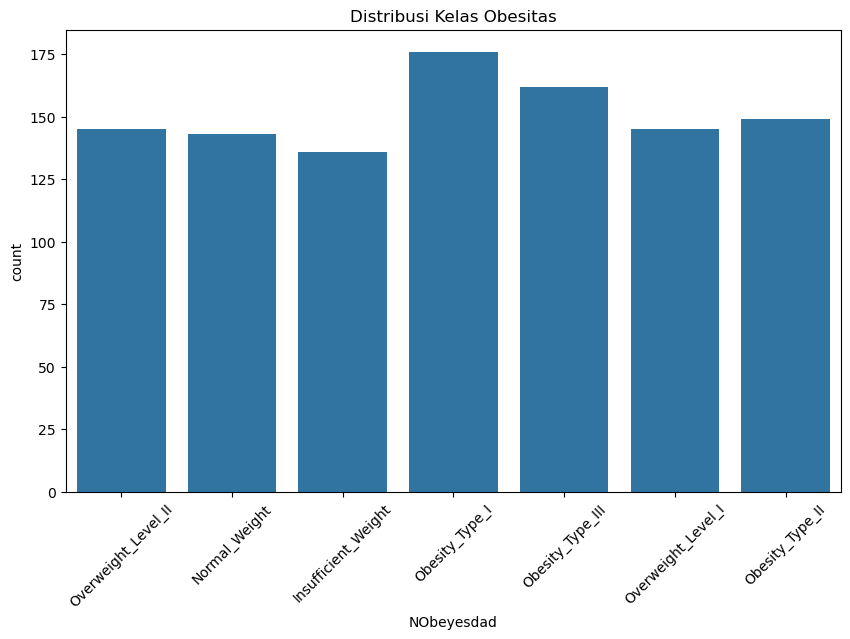

In [22]:
plt.figure(figsize=(10,6))
sns.countplot(data=df, x='NObeyesdad')
plt.title('Distribusi Kelas Obesitas')
plt.xticks(rotation=45)
plt.show()

Analyze Numerical Features

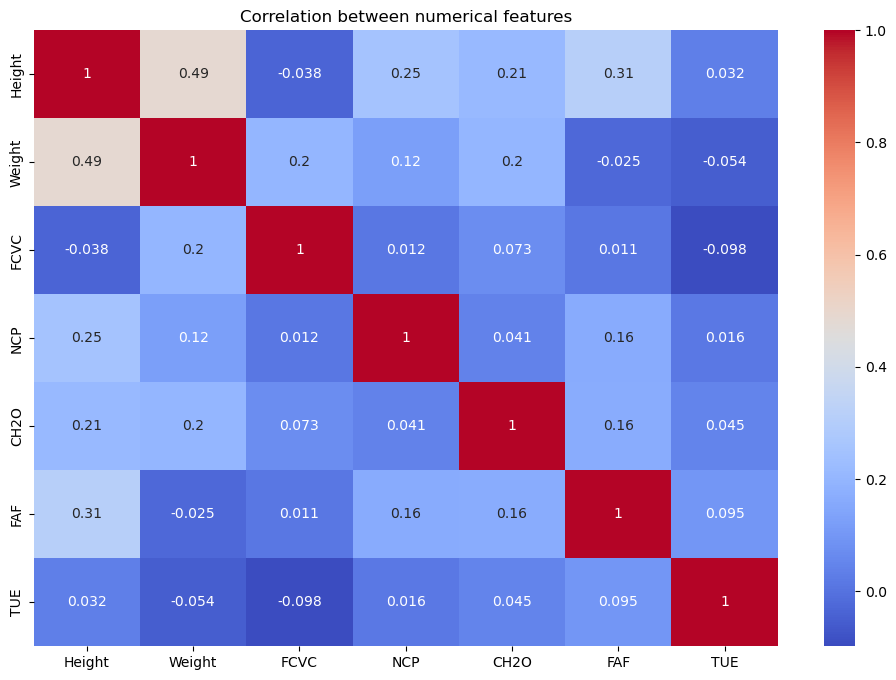

In [24]:
plt.figure(figsize=(12,8))
corr_matrix = df.corr(numeric_only=True)
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation between numerical features')
plt.show()

Add Feature BMI

In [26]:
df['BMI'] = df['Weight'] / (df['Height'] ** 2)

**B) Data Preparation**

Split Data for Training & Testing

In [29]:
X = df.drop('NObeyesdad', axis=1)
y = df['NObeyesdad']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Identify Numerical & Categorical Features

In [31]:
categorical_cols = X_train.select_dtypes(include=['object']).columns
numerical_cols = X_train.select_dtypes(include=['int64', 'float64']).columns

Handling Missing Values for Numerical Features

In [33]:
for col in numerical_cols:
  X_train[numerical_cols] = X_train[numerical_cols].fillna(X_train[numerical_cols].median())
  X_test[numerical_cols] = X_test[numerical_cols].fillna(X_train[numerical_cols].median())

Handling Missing Values for Categorical Features

In [35]:
for col in categorical_cols:
  X_train[categorical_cols] = X_train[categorical_cols].fillna(X_train[categorical_cols].mode().iloc[0])
  X_test[categorical_cols] = X_test[categorical_cols].fillna(X_train[categorical_cols].mode().iloc[0])

In [36]:
missing_values = X_train.isnull().sum()
print(missing_values)

Gender                            0
Age                               0
Height                            0
Weight                            0
family_history_with_overweight    0
FAVC                              0
FCVC                              0
NCP                               0
CAEC                              0
SMOKE                             0
CH2O                              0
SCC                               0
FAF                               0
TUE                               0
CALC                              0
MTRANS                            0
BMI                               0
dtype: int64


Handling Outliers

In [38]:
for col in numerical_cols:
  Q1 = X_train[col].quantile(0.25)
  Q3 = X_train[col].quantile(0.75)
  IQR = Q3 - Q1

  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  X_train[col] = X_train[col].clip(lower=lower_bound, upper=upper_bound)
  X_test[col] = X_test[col].clip(lower=lower_bound, upper=upper_bound)

In [39]:
print("Outliers in X_train after clipping:")
for col in numerical_cols:
  Q1_clipped = X_train[col].quantile(0.25)
  Q3_clipped = X_train[col].quantile(0.75)
  IQR_clipped = Q3_clipped - Q1_clipped

  outliers_clipped_train = ((X_train[col] < (Q1_clipped - 1.5 * IQR_clipped)) | (X_train[col] > (Q3_clipped + 1.5 * IQR_clipped)))
  outliers_count_clipped_train = outliers_clipped_train.sum()
  print(f'{col}: {outliers_count_clipped_train} outliers')

Outliers in X_train after clipping:
Height: 0 outliers
Weight: 0 outliers
FCVC: 0 outliers
NCP: 0 outliers
CH2O: 0 outliers
FAF: 0 outliers
TUE: 0 outliers
BMI: 0 outliers


Encoding Categorical Features

In [41]:
label_encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    X_train[col] = le.fit_transform(X_train[col])

    mapping = dict(zip(le.classes_, le.transform(le.classes_)))
    X_test[col] = X_test[col].map(mapping).fillna(-1).astype(int)

    label_encoders[col] = le

Scaling Numerical Data

In [43]:
scaler = StandardScaler()
X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])

Encode Target Label

In [45]:
target_encoder = LabelEncoder()
y_train = target_encoder.fit_transform(y_train)
y_test = target_encoder.transform(y_test)

Training Model Random Forest

In [47]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_predictions)
print("Random Forest Accuracy:", rf_accuracy)
print(classification_report(y_test, rf_predictions))

Random Forest Accuracy: 0.9858490566037735
              precision    recall  f1-score   support

           0       1.00      0.96      0.98        27
           1       0.97      1.00      0.99        36
           2       1.00      1.00      1.00        34
           3       1.00      0.97      0.99        34
           4       0.97      1.00      0.98        32
           5       1.00      0.96      0.98        26
           6       0.96      1.00      0.98        23

    accuracy                           0.99       212
   macro avg       0.99      0.99      0.99       212
weighted avg       0.99      0.99      0.99       212



Training Model XGBoost

In [49]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', random_state=42)
xgb_model.fit(X_train, y_train)
xgb_predictions = xgb_model.predict(X_test)
xgb_accuracy = accuracy_score(y_test, xgb_predictions)
print("XGBoost Accuracy:", xgb_accuracy)
print(classification_report(y_test, xgb_predictions))

C:\Users\Alessandro Moreno\anaconda3\Lib\site-packages\xgboost\training.py:183: UserWarning: [04:08:30] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Accuracy: 0.9716981132075472
              precision    recall  f1-score   support

           0       0.96      0.93      0.94        27
           1       0.95      0.97      0.96        36
           2       0.97      1.00      0.99        34
           3       1.00      0.94      0.97        34
           4       0.97      1.00      0.98        32
           5       1.00      0.96      0.98        26
           6       0.96      1.00      0.98        23

    accuracy                           0.97       212
   macro avg       0.97      0.97      0.97       212
weighted avg       0.97      0.97      0.97       212



Save Best Model With Pickle

In [51]:
if rf_accuracy >= xgb_accuracy:
    best_model = rf_model
    best_model_name = "random_forest"
else:
    best_model = xgb_model
    best_model_name = "xgboost"

import pickle
with open(f"best_model_{best_model_name}.pkl", "wb") as f:
    pickle.dump(best_model, f)

with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

with open("label_encoders.pkl", "wb") as f:
    pickle.dump(label_encoders, f)

with open("target_encoder.pkl", "wb") as f:
    pickle.dump(target_encoder, f)